# Hierarchical Clustering
**Aim:** To implement Hierarchical (Agglomerative) clustering algorithm.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

### Create data

(150, 2)


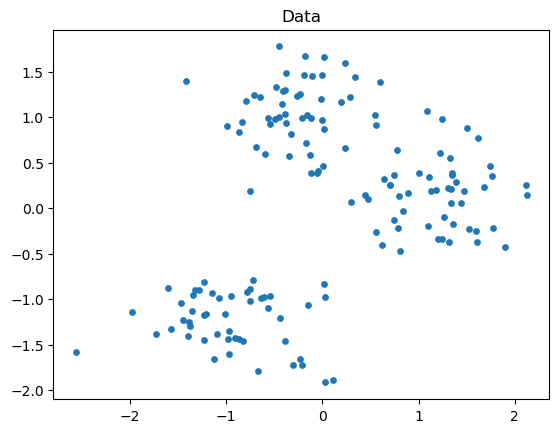

In [2]:
X, y = make_blobs(n_samples=150, centers=3, cluster_std=2.5, random_state=42)
X = StandardScaler().fit_transform(X)
print(X.shape)

plt.scatter(X[:,0], X[:,1], s=15)
plt.title("Data")
plt.show()

### Dendrogram

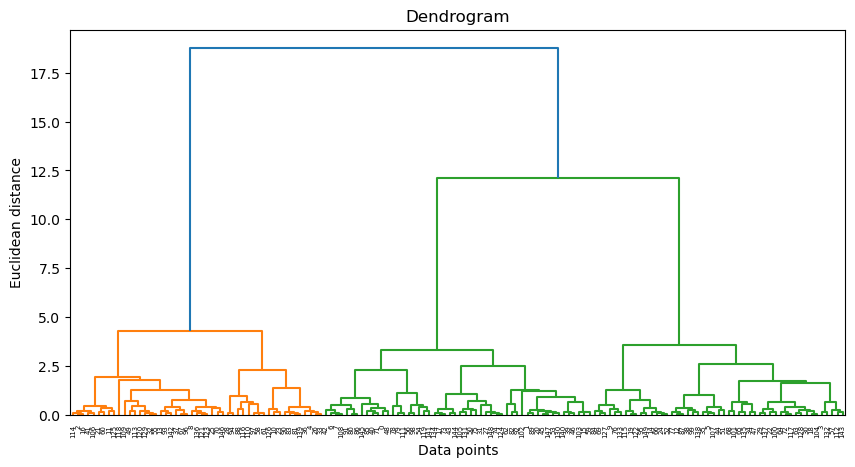

In [3]:
plt.figure(figsize=(10,5))
dend = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title("Dendrogram")
plt.xlabel("Data points")
plt.ylabel("Euclidean distance")
plt.show()

### Apply Agglomerative clustering

In [4]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = hc.fit_predict(X)

print("Cluster labels:", np.unique(labels))
print("Silhouette score:", silhouette_score(X, labels))

Cluster labels: [0 1 2]
Silhouette score: 0.6086083637154209


### Plot clusters

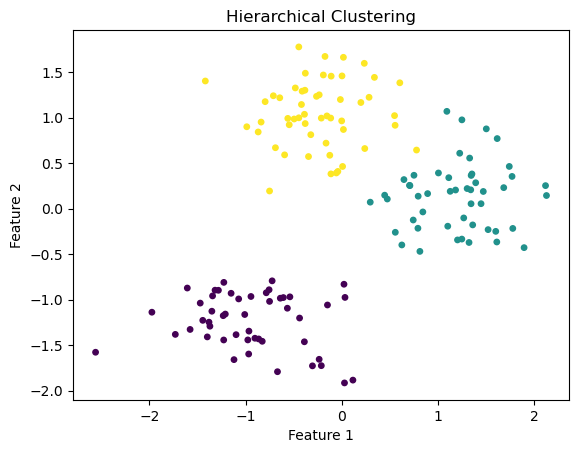

In [5]:
plt.scatter(X[:,0], X[:,1], c=labels, cmap='viridis', s=15)
plt.title("Hierarchical Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### Different linkage methods

In [6]:
for m in ['ward', 'complete', 'average', 'single']:
    h = AgglomerativeClustering(n_clusters=3, linkage=m)
    l = h.fit_predict(X)
    print(m, "silhouette score =", silhouette_score(X, l))

ward silhouette score = 0.6086083637154209
complete silhouette score = 0.6146445580317642
average silhouette score = 0.6090450504714785
single silhouette score = 0.500635348628465


**Conclusion:** Hierarchical clustering was implemented using agglomerative method. The dendrogram helps to decide the number of clusters, and 3 clusters were formed. Different linkage methods give different silhouette scores.